# 1. Setup and Data Loading

## 1.1 Import Required Libraries

In [ ]:
!pip -q install xgboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)


## 1.2 Authenticate Google Colab and Connect to BigQuery

In [ ]:
from google.colab import auth
auth.authenticate_user()

from google.cloud import bigquery

client = bigquery.Client(project="ba878-team02")

query = """
SELECT *
FROM `ba878-team02.ckd_readmission.ckd_readmission_clean`
"""

df = client.query(query).to_dataframe()

print(df.shape)


(79483, 23)


Our cleaned dataset contains 79,483 rows and 23 columns, where each row represents one hospital admission and the columns include patient characteristics, hospitalization information, comorbidities, and the 30-day readmission outcome.

# 2. Exploratory Data Analysis (EDA)

 ## 2.1 Data Summary

In [ ]:
print("Unique patients:", df["subject_id"].nunique())

admissions_per_patient = df.groupby("subject_id").size()

print("Patients with multiple hospitalizations:",
      (admissions_per_patient > 1).sum())

print("30-day readmission rate:",
      round(df["readmitted_30d"].mean() * 100, 2), "%")

Unique patients: 27826
Patients with multiple hospitalizations: 13719
30-day readmission rate: 25.76 %


Our cleaned dataset contains 79,483 hospitalizations from 27,826 unique patients. Among these patients, 13,719 had multiple hospitalizations, indicating the importance of using patient-level data splitting to prevent the same patient from appearing in both training and testing sets.

The 30-day readmission rate is 25.76%, compared with 74.24% without readmission, indicating a imbalanced dataset. Therefore, we should consider class imbalance during model training and focus on evaluation metrics such as AUROC, AUPRC, precision, recall, and F1-score rather than relying only on accuracy.

## 2.2 Missing Value

### 2.2.1 Missing Values Overview

,Missing Count,Missing Percentage
days_to_readmission,21681,27.277531
next_admittime,21681,27.277531
marital_status,1324,1.665765
insurance,226,0.284338
admittime,0,0.000000
hadm_id,0,0.000000
subject_id,0,0.000000
admission_location,0,0.000000
admission_type,0,0.000000
dischtime,0,0.000000


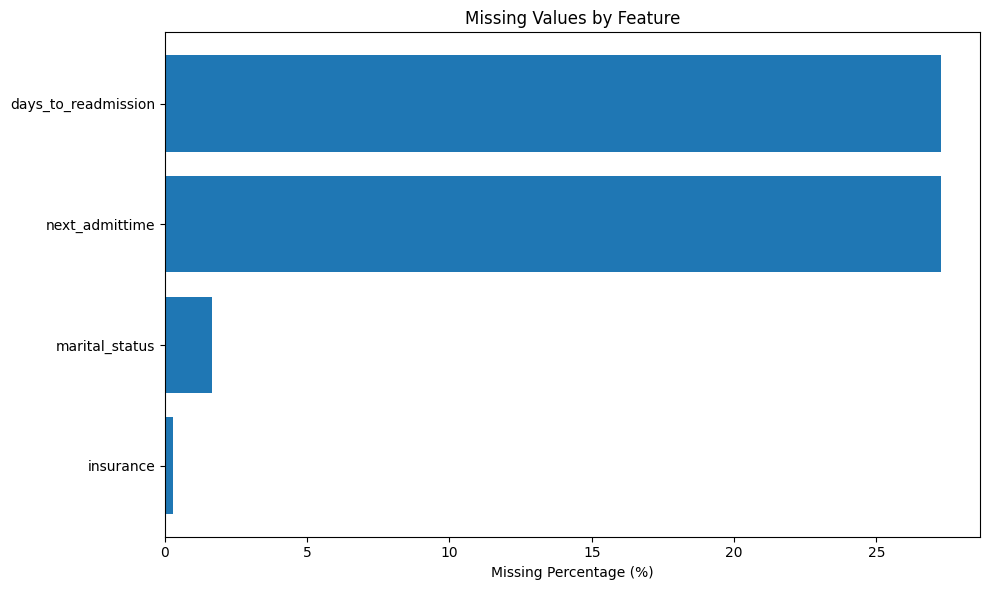

In [ ]:
missing_df = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing_df = missing_df.sort_values(
    "Missing Percentage", ascending=False
)

display(missing_df)

missing_plot = missing_df[
    missing_df["Missing Percentage"] > 0
]

plt.figure(figsize=(10, 6))
plt.barh(
    missing_plot.index,
    missing_plot["Missing Percentage"]
)
plt.xlabel("Missing Percentage (%)")
plt.title("Missing Values by Feature")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

The missing-value analysis shows that most variables in our dataset are complete. The highest missing rates are found in `next_admittime` and `days_to_readmission`, both at 27.28%. In comparison, `marital_status` and `insurance` have much lower missing rates of 1.67% and 0.28%, respectively.

For marital_status and insurance, missing values will be handled using most-frequent imputation during preprocessing.

### 2.2.2 Missing Readmission Information

In [ ]:
readmission_missing = pd.crosstab(
    df["next_admittime"].isna(),
    df["readmitted_30d"],
    rownames=["Next Admission Missing"],
    colnames=["Readmitted Within 30 Days"],
    margins=True
)

display(readmission_missing)

Readmitted Within 30 Days,0,1,All
Next Admission Missing,,,
False,37330,20472,57802
True,21681,0,21681
All,59011,20472,79483


In this table, `True` means there is no subsequent hospital admission recorded, while `False` means a subsequent admission is recorded. For `readmitted_30d`, `0` represents no readmission within 30 days, and `1` represents readmission within 30 days.

According to the table, 21,681 hospitalizations have no subsequent admission recorded and are labeled as not readmitted within 30 days. This suggests that the missing values are related to the absence of subsequent admission records rather than a data quality issue. However, these patients may have been readmitted to other hospitals that are not captured in the MIMIC-IV dataset.

## 2.3 Demographic Analysis

### 2.3.1 Age Distribution

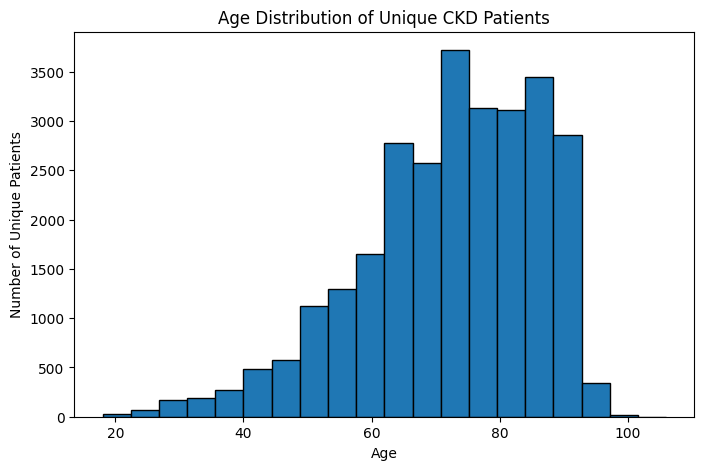

Total unique patients: 27826


In [ ]:
unique_patients = (
    df.sort_values("admittime")
      .drop_duplicates(subset="subject_id", keep="first")
)

plt.figure(figsize=(8, 5))

plt.hist(
    unique_patients["age"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.xlabel("Age")
plt.ylabel("Number of Unique Patients")
plt.title("Age Distribution of Unique CKD Patients")
plt.show()

print("Total unique patients:", unique_patients["subject_id"].nunique())


The age distribution of 27,826 patients shows that most patients are older adults, with the majority concentrated between approximately 60 and 90 years old.

### 2.3.2 Readmission rate by age group

,mean,count
age_group,,
<40,21.41,738
40-49,19.87,1233
50-59,21.65,2975
60-69,19.45,5634
70-79,18.4,7482
80+,16.95,9764


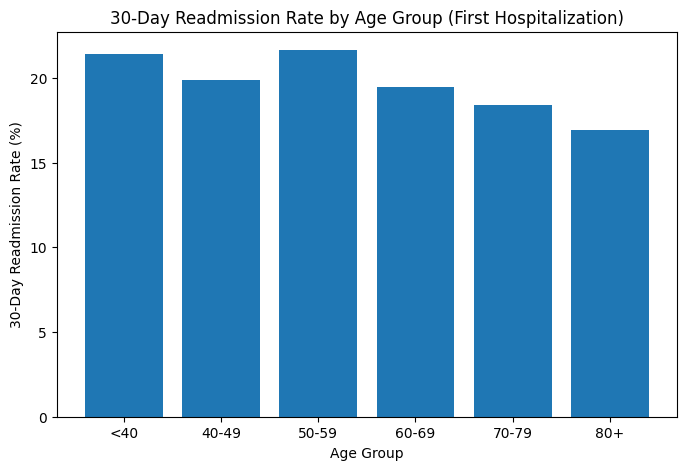

In [ ]:
unique_patients = (
    df.sort_values("admittime")
      .drop_duplicates(subset="subject_id", keep="first")
      .copy()
)

unique_patients["age_group"] = pd.cut(
    unique_patients["age"],
    bins=[0, 40, 50, 60, 70, 80, float("inf")],
    labels=["<40", "40-49", "50-59", "60-69", "70-79", "80+"],
    include_lowest=True,
    right=False
)


age_readmission = unique_patients.groupby(
    "age_group", observed=True
)["readmitted_30d"].agg(["mean", "count"])

age_readmission["mean"] *= 100

display(age_readmission.round(2))

plt.figure(figsize=(8, 5))

plt.bar(
    age_readmission.index.astype(str),
    age_readmission["mean"]
)

plt.xlabel("Age Group")
plt.ylabel("30-Day Readmission Rate (%)")
plt.title("30-Day Readmission Rate by Age Group (First Hospitalization)")
plt.show()


The analysis shows that 30-day readmission rates generally decrease with age. Patients aged 50–59 have the highest readmission rate (21.65%), followed by patients under 40 (21.41%), while patients aged 80 and above have the lowest rate (16.95%).

Although older age groups contain more patients, younger and middle-aged patients tend to have higher readmission rates.

### 2.4.3 Readmission rate by gender


,mean,count
gender,,
F,18.27,11257
M,18.82,16569


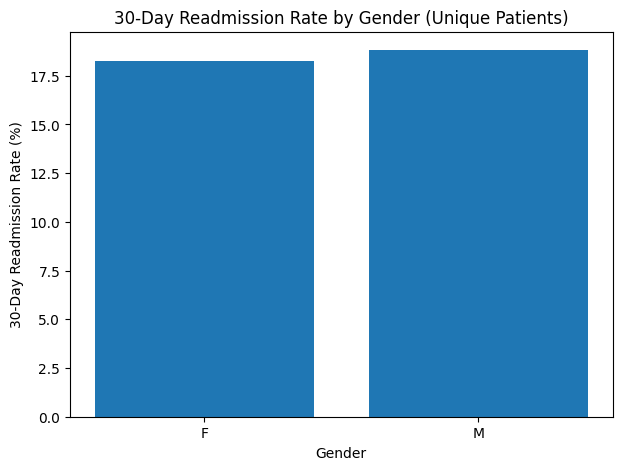

In [ ]:
gender_readmission = unique_patients.groupby(
    "gender"
)["readmitted_30d"].agg(["mean", "count"])


gender_readmission["mean"] *= 100

display(gender_readmission.round(2))


plt.figure(figsize=(7, 5))

plt.bar(
    gender_readmission.index.astype(str),
    gender_readmission["mean"]
)

plt.xlabel("Gender")
plt.ylabel("30-Day Readmission Rate (%)")
plt.title("30-Day Readmission Rate by Gender (Unique Patients)")
plt.show()


The analysis shows that male patients have a slightly higher 30-day readmission rate (18.82%) than female patients (18.27%). The difference is only 0.55 percentage points.

Additionally, our dataset contains more male patients (16,569) than female patients (11,257). Further modeling is needed to determine whether gender contributes meaningful predictive information when combined with other patient characteristics.

## 2.4 Hospitalization Characteristics

### 2.4.1 Length of Stay by 30-Day Readmission Status

,count,mean,std,min,25%,50%,75%,max
readmitted_30d,,,,,,,,
0,22651.0,6.425528,8.297028,0.041667,2.00,4.041667,7.750000,308.958333
1,5175.0,8.365644,10.617278,0.041667,2.75,5.458333,9.791667,151.083333


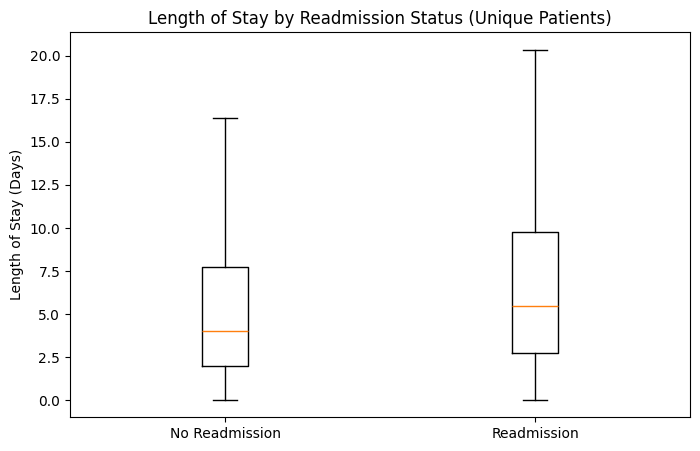

In [ ]:
display(
    unique_patients.groupby("readmitted_30d")["length_of_stay"]
    .describe()
)


plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        unique_patients.loc[
            unique_patients["readmitted_30d"] == 0,
            "length_of_stay"
        ].dropna(),

        unique_patients.loc[
            unique_patients["readmitted_30d"] == 1,
            "length_of_stay"
        ].dropna()
    ],
    tick_labels=["No Readmission", "Readmission"],
    showfliers=False
)

plt.ylabel("Length of Stay (Days)")
plt.title("Length of Stay by Readmission Status (Unique Patients)")
plt.show()



The analysis shows that patients who were readmitted within 30 days generally had longer initial hospital stays. The average length of stay was 8.37 days for readmitted patients, compared with 6.43 days for those who were not readmitted. Similarly, the median length of stay was 5.46 days versus 4.04 days.

### 2.4.2 30-Day Readmission Rate by Admission Type

,mean,count
admission_type,,
EW EMER.,18.36,11811
OBSERVATION ADMIT,17.21,5589
URGENT,21.13,3181
EU OBSERVATION,12.5,2368
SURGICAL SAME DAY ADMISSION,18.27,1795
DIRECT EMER.,30.67,1177
DIRECT OBSERVATION,19.04,961
ELECTIVE,23.11,623
AMBULATORY OBSERVATION,19.0,321


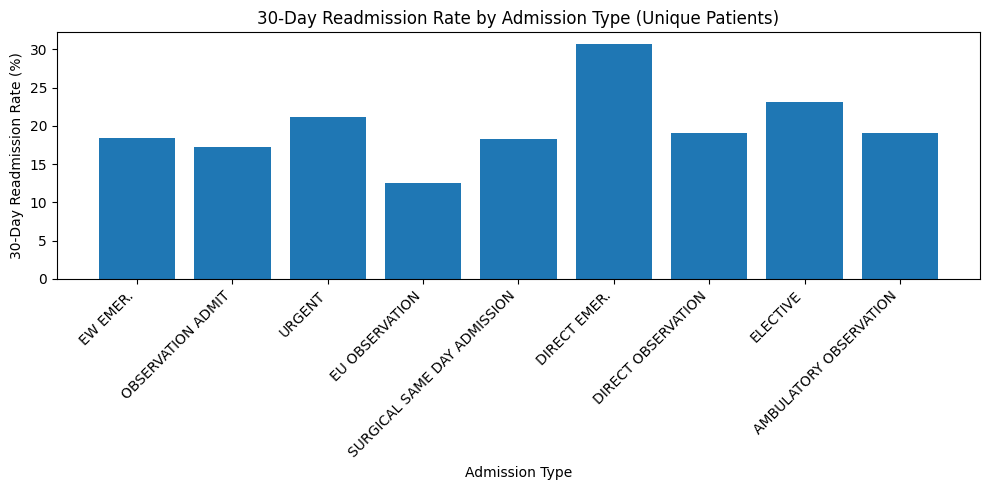

In [ ]:
admission_rates = (
    unique_patients.groupby("admission_type")["readmitted_30d"]
    .agg(["mean", "count"])
    .sort_values("count", ascending=False)
)


admission_rates["mean"] *= 100

display(admission_rates.round(2))


plt.figure(figsize=(10, 5))

plt.bar(
    admission_rates.index.astype(str),
    admission_rates["mean"]
)

plt.xticks(rotation=45, ha="right")
plt.xlabel("Admission Type")
plt.ylabel("30-Day Readmission Rate (%)")
plt.title("30-Day Readmission Rate by Admission Type (Unique Patients)")
plt.tight_layout()
plt.show()

The analysis shows that 30-day readmission rates vary across admission types among patients. Direct emergency admissions have the highest readmission rate (30.67%), while EU observation admissions have the lowest rate (12.50%).

Although EW emergency admissions account for the largest number of patients (11,811), their readmission rate is 18.36%. This suggests that admission type may be associated with 30-day readmission risk and could be a useful predictor for our model.

## 2.5 Comorbidity Analysis

,Comorbidity,Patient Hospitalizations,Prevalence (%),Readmission Rate (%)
0,diabetes,41844,52.65,26.86
1,heart_failure,34806,43.79,27.80
2,hypertension,70523,88.73,25.58
3,copd,14519,18.27,27.01
4,obesity,10659,13.41,24.64


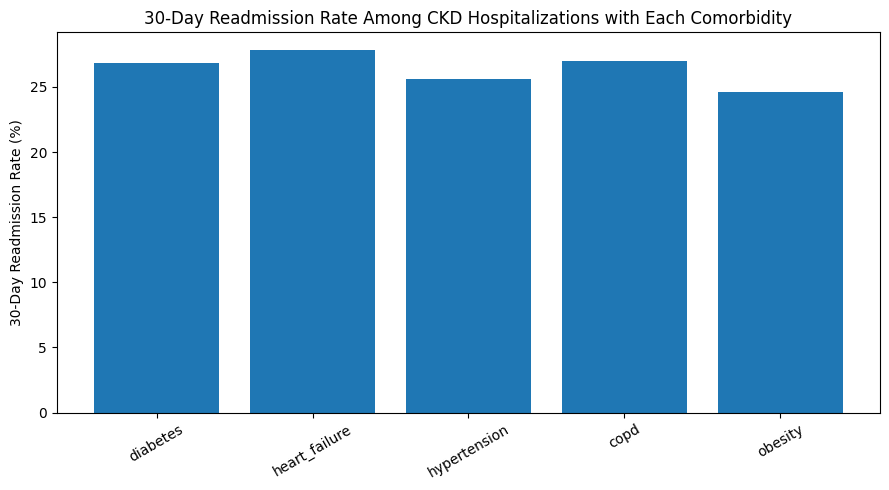

In [ ]:

comorbidities = [
    "diabetes",
    "heart_failure",
    "hypertension",
    "copd",
    "obesity"
]

comorbidity_results = []

for disease in comorbidities:
    subset = df[df[disease] == 1]

    comorbidity_results.append({
        "Comorbidity": disease,
        "Patient Hospitalizations": len(subset),
        "Prevalence (%)": df[disease].mean() * 100,
        "Readmission Rate (%)": subset["readmitted_30d"].mean() * 100
    })

comorbidity_df = pd.DataFrame(comorbidity_results)

display(comorbidity_df.round(2))

plt.figure(figsize=(9, 5))

plt.bar(
    comorbidity_df["Comorbidity"],
    comorbidity_df["Readmission Rate (%)"]
)

plt.ylabel("30-Day Readmission Rate (%)")
plt.title("30-Day Readmission Rate Among CKD Hospitalizations with Each Comorbidity")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


The comorbidity analysis shows that hypertension is the most common condition among CKD hospitalizations (88.73%), followed by diabetes (52.65%) and heart failure (43.79%).

Although hypertension has the highest prevalence, heart failure has the highest 30-day readmission rate (27.80%), followed by COPD (27.01%) and diabetes (26.86%). Obesity has the lowest readmission rate (24.64%) among the five conditions.

These findings suggest that different comorbidities may be associated with different readmission risks and could provide useful information for our prediction model.

## 2.6 Multimorbidity Analysis

### 2.6.1 Distribution of Comorbidity Count

,count
comorbidity_count,
0,3418
1,18359
2,28706
3,20686
4,7048
5,1266


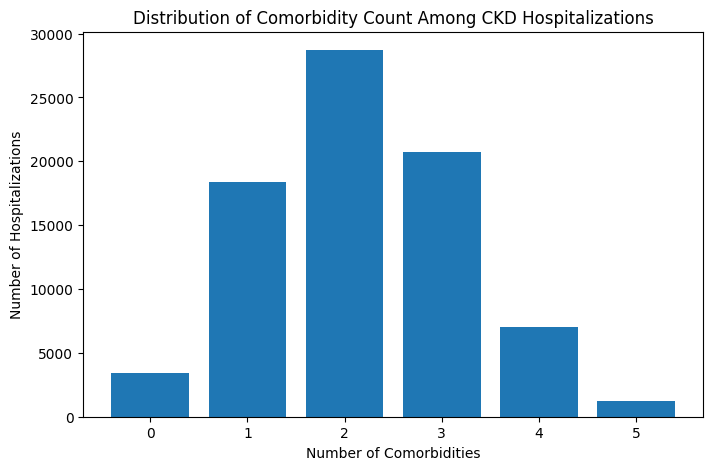

In [ ]:
comorbidity_counts = (
    df["comorbidity_count"]
    .value_counts()
    .sort_index()
)

display(comorbidity_counts)

plt.figure(figsize=(8, 5))

plt.bar(
    comorbidity_counts.index.astype(str),
    comorbidity_counts.values
)

plt.xlabel("Number of Comorbidities")
plt.ylabel("Number of Hospitalizations")
plt.title("Distribution of Comorbidity Count Among CKD Hospitalizations")
plt.show()


The analysis shows that most CKD hospitalizations involve multiple comorbidities. The largest group has two additional comorbidities (36.12%), followed by three comorbidities (26.03%). Overall, approximately 72.60% of hospitalizations involve at least two additional comorbidities, while only 4.30% have none of the five conditions.

The multimorbidity is common among CKD hospitalizations and may be an important factor to consider when predicting 30-day readmission.

### 2.6.2 Readmission Rate by Comorbidity Count

,mean,count,readmission_rate_pct
comorbidity_count,,,
0,0.26,3418,25.83
1,0.24,18359,23.98
2,0.25,28706,24.79
3,0.28,20686,27.97
4,0.27,7048,27.09
5,0.3,1266,29.62


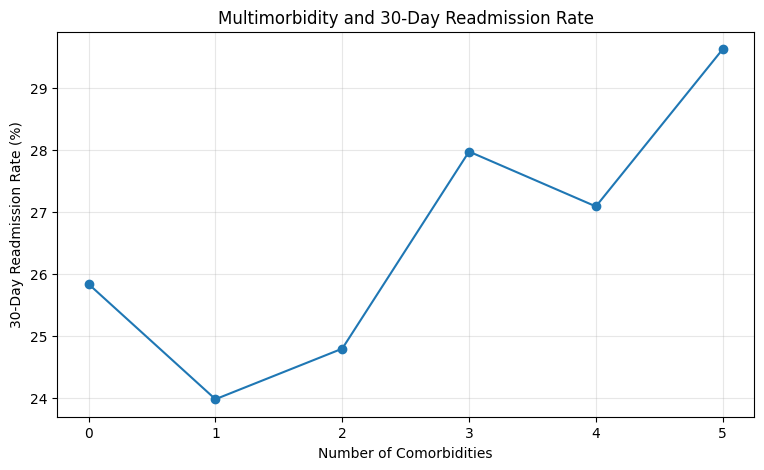

In [ ]:

multimorbidity = (
    df.groupby("comorbidity_count")["readmitted_30d"]
      .agg(["mean", "count"])
      .sort_index()
)

multimorbidity["readmission_rate_pct"] = (
    multimorbidity["mean"] * 100
)

display(multimorbidity.round(2))

plt.figure(figsize=(9, 5))

plt.plot(
    multimorbidity.index,
    multimorbidity["readmission_rate_pct"],
    marker="o"
)

plt.xlabel("Number of Comorbidities")
plt.ylabel("30-Day Readmission Rate (%)")
plt.title("Multimorbidity and 30-Day Readmission Rate")
plt.grid(alpha=0.3)
plt.show()


The analysis shows that 30-day readmission rates generally increase as the number of comorbidities rises. Hospitalizations with five comorbidities have the highest readmission rate (29.62%), followed by those with three comorbidities (27.97%) and four comorbidities (27.09%). In contrast, hospitalizations with one comorbidity have the lowest readmission rate (23.98%).

Overall, these findings suggest that greater multimorbidity may be associated with a higher risk of 30-day readmission among CKD hospitalizations.

## 2.7 Previous Healthcare Utilization

prior_admissions_365d        prior_ed_visits_365d         \
                                mean median                 mean median   
readmitted_30d                                                            
0                               1.43    1.0                 0.77    0.0   
1                               2.88    2.0                 1.46    0.0   

               medication_count         
                           mean median  
readmitted_30d                          
0                         26.68   24.0  
1                         29.64   27.0

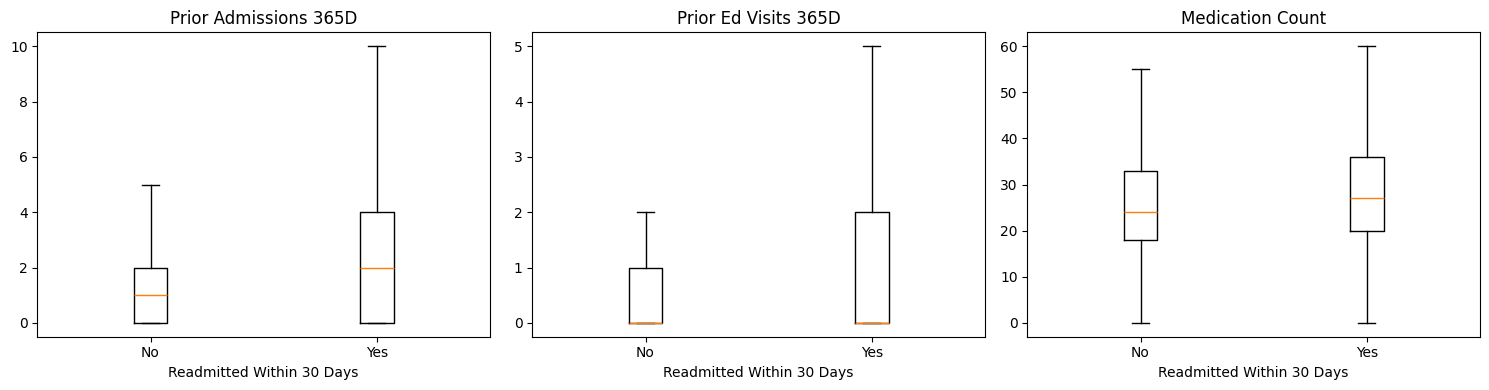

In [ ]:

utilization_features = [
    "prior_admissions_365d",
    "prior_ed_visits_365d",
    "medication_count"
]


utilization_summary = df.groupby(
    "readmitted_30d"
)[utilization_features].agg(["mean", "median"])

display(utilization_summary.round(2))


fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, utilization_features):
    groups = [
        df.loc[df["readmitted_30d"] == status, feature].dropna()
        for status in [0, 1]
    ]

    ax.boxplot(
        groups,
        tick_labels=["No", "Yes"],
        showfliers=False
    )

    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("Readmitted Within 30 Days")

plt.tight_layout()
plt.show()


The analysis shows that CKD hospitalizations followed by a 30-day readmission generally have higher previous healthcare utilization. The readmitted group had an average of 2.88 prior hospital admissions, compared with 1.43 in the non-readmitted group. Similarly, the average number of prior ED visits was 1.46 versus 0.77.

The readmitted group also had a higher average medication count (29.64) compared with the non-readmitted group (26.68).

These findings suggest that previous healthcare utilization and medication burden may be useful predictors of 30-day readmission among CKD patients.

## 2.8 Correlation Analysis

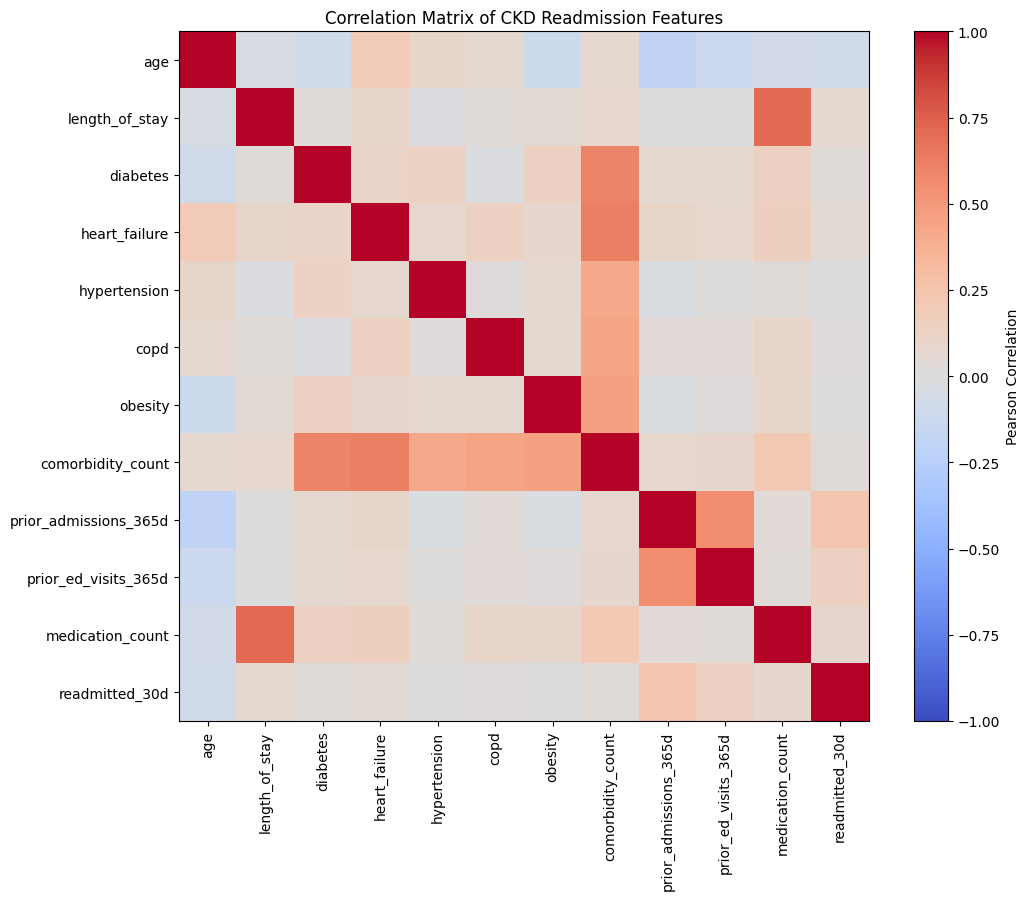

In [ ]:

correlation_features = [
    "age",
    "length_of_stay",
    "diabetes",
    "heart_failure",
    "hypertension",
    "copd",
    "obesity",
    "comorbidity_count",
    "prior_admissions_365d",
    "prior_ed_visits_365d",
    "medication_count",
    "readmitted_30d"
]

corr_matrix = df[correlation_features].corr()

plt.figure(figsize=(11, 9))

plt.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Pearson Correlation")

plt.xticks(
    range(len(correlation_features)),
    correlation_features,
    rotation=90
)

plt.yticks(
    range(len(correlation_features)),
    correlation_features
)

plt.title("Correlation Matrix of CKD Readmission Features")
plt.tight_layout()
plt.show()


The correlation analysis shows that prior hospital admissions have a positive correlation with 30-day readmission, while age has a weak negative correlation with readmission.

We also found a relatively strong positive correlation between length of stay and medication count, suggesting that longer hospital stays tend to involve more medication records. Additionally, comorbidity count is positively correlated with individual chronic conditions, which is expected because these conditions contribute to the count.

Overall, most individual predictors have relatively weak linear correlations with 30-day readmission.

# 3. Data Preprocessing and Feature Engineering

## 3.1 Define Predictors and Target Variable

In [ ]:

numeric_features = [
    "age",
    "length_of_stay",
    "diabetes",
    "heart_failure",
    "hypertension",
    "copd",
    "obesity",
    "prior_admissions_365d",
    "prior_ed_visits_365d",
    "medication_count"
]

categorical_features = [
    "gender",
    "admission_type",
    "admission_location",
    "insurance",
    "marital_status"
]

features = numeric_features + categorical_features

X = df[features].copy()

y = df["readmitted_30d"].astype(int)

print("Predictors:", X.shape)
print("\nTarget distribution:")
print(y.value_counts(normalize=True))

Predictors: (79483, 15)

Target distribution:
readmitted_30d
0    0.742435
1    0.257565
Name: proportion, dtype: float64


## 3.2 Train-Test Split

We used patient-level splitting with `GroupShuffleSplit` to divide our dataset into training and testing sets. Since some CKD patients have multiple hospitalizations, this approach ensures that all records belonging to the same patient remain in the same dataset.

This helps prevent patient overlap between training and testing sets and reduces the risk of data leakage.

In [ ]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        X,
        y,
        groups=df["subject_id"]
    )
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

print("\nTraining readmission rate:",
      round(y_train.mean(), 4))
print("Testing readmission rate:",
      round(y_test.mean(), 4))

Training: (64281, 15)
Testing: (15202, 15)

Training readmission rate: 0.2588
Testing readmission rate: 0.2521


## 3.3 Create Validation Set

In [ ]:
val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=123
)

train_sub_idx, val_idx = next(
    val_splitter.split(
        X_train,
        y_train,
        groups=df.iloc[train_idx]["subject_id"]
    )
)

X_train_final = X_train.iloc[train_sub_idx]
X_val = X_train.iloc[val_idx]

y_train_final = y_train.iloc[train_sub_idx]
y_val = y_train.iloc[val_idx]

print("Training:", X_train_final.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


Training: (51524, 15)
Validation: (12757, 15)
Testing: (15202, 15)


## 3.4 Data Transformation

In [ ]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="first"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train_final)

X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)


Training: (51524, 38)
Validation: (12757, 38)
Testing: (15202, 38)


# 4. Logistic Regression Model Training

In [ ]:
# Train Logistic Regression on training data only

lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train model
lr_model.fit(X_train_final, y_train_final)

# Predict probabilities on validation data
y_val_prob = lr_model.predict_proba(X_val)[:, 1]

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [ ]:
#Find the best threshold using validation data:

thresholds = [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]

results = []

for threshold in thresholds:
    predictions = (y_val_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_results_val = pd.DataFrame(results)

display(threshold_results_val.round(4))

best_row = threshold_results_val.loc[
    threshold_results_val["F1"].idxmax()
]

best_threshold = float(best_row["Threshold"])

print("\nBest validation threshold:", best_threshold)
print("Best validation F1:", round(best_row["F1"], 4))

,Threshold,Precision,Recall,F1
0,0.15,0.2602,0.9814,0.4113
1,0.20,0.3004,0.7993,0.4366
2,0.25,0.3541,0.5587,0.4335
3,0.30,0.4079,0.3906,0.3990
4,0.35,0.4504,0.2781,0.3439
5,0.40,0.4923,0.1998,0.2843
6,0.50,0.5419,0.1004,0.1694



Best validation threshold: 0.2
Best validation F1: 0.4366


In [ ]:
#Evaluate finalized Logistic Regression:

# Use threshold selected on validation data
y_test_prob = lr_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_prob >= best_threshold).astype(int)

print("Final Logistic Regression Results")
print("Threshold:", best_threshold)

print("AUROC:", round(
    roc_auc_score(y_test, y_test_prob), 4
))
print("AUPRC:", round(
    average_precision_score(y_test, y_test_prob), 4
))
print("Precision:", round(
    precision_score(y_test, y_test_pred), 4
))
print("Recall:", round(
    recall_score(y_test, y_test_pred), 4
))
print("F1:", round(
    f1_score(y_test, y_test_pred), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Final Logistic Regression Results
Threshold: 0.2
AUROC: 0.6519
AUPRC: 0.4056
Precision: 0.3032
Recall: 0.7869
F1: 0.4377

Confusion Matrix:
[[4438 6931]
 [ 817 3016]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.39      0.53     11369
           1       0.30      0.79      0.44      3833

    accuracy                           0.49     15202
   macro avg       0.57      0.59      0.49     15202
weighted avg       0.71      0.49      0.51     15202



At threshold 0.20, the model correctly identifies 3,016 readmissions but incorrectly flags 6,931 hospitalizations.
Conclusion: Logistic Regression provides a useful baseline, but its ability to distinguish high-risk patients is limited.

# 5. XGBoost Model

## 5.1 Handle Class Imbalance

In [ ]:
positive = (y_train_final == 1).sum()
negative = (y_train_final == 0).sum()

print("Readmissions:", positive)
print("No readmissions:", negative)

scale_pos_weight = negative / positive

print("Scale pos weight:", round(scale_pos_weight, 2))


Readmissions: 13421
No readmissions: 38103
Scale pos weight: 2.84


The training dataset contains 13,421 readmission cases and 38,103 non-readmission cases, indicating class imbalance.

To address this, we calculated `scale_pos_weight = 2.84`, which assigns approximately 2.84 times more weight to readmission cases during XGBoost training. This helps the model pay more attention to the minority class.

## 5.2 XGBoost Model Training

In [ ]:
xgb_model = XGBClassifier(
    objective="binary:logistic",
    n_estimators=1000,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    tree_method="hist",
    eval_metric="aucpr",
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1
)


xgb_model.fit(
    X_train_processed,
    y_train_final,
    eval_set=[(X_val_processed, y_val)],
    verbose=False
)

print("XGBoost training completed!")
print("Best iteration:", xgb_model.best_iteration)
print("Best validation AUPRC:", xgb_model.best_score)


XGBoost training completed!
Best iteration: 56
Best validation AUPRC: 0.40938239641074


According to the XGBoost training results, the best iteration was 56, and the validation Area Under the Precision-Recall Curve (AUPRC) was 0.4094. This is higher than the approximate baseline of 0.26, suggesting that the model has learned useful patterns for predicting 30-day readmission among CKD patients.

## 5.3 XGBoost Validation Performance Evaluation

In [ ]:
y_val_prob = xgb_model.predict_proba(
    X_val_processed
)[:, 1]

y_val_pred = (y_val_prob >= 0.5).astype(int)

print("Validation Performance")
print("----------------------")

print("AUROC:",
      round(roc_auc_score(y_val, y_val_prob), 4))

print("AUPRC:",
      round(average_precision_score(y_val, y_val_prob), 4))

print("Precision:",
      round(precision_score(y_val, y_val_pred,
                            zero_division=0), 4))

print("Recall:",
      round(recall_score(y_val, y_val_pred,
                         zero_division=0), 4))

print("F1:",
      round(f1_score(y_val, y_val_pred,
                     zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    zero_division=0
))


Validation Performance
----------------------
AUROC: 0.6598
AUPRC: 0.4096
Precision: 0.3587
Recall: 0.574
F1: 0.4415

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.65      0.73      9539
           1       0.36      0.57      0.44      3218

    accuracy                           0.63     12757
   macro avg       0.59      0.61      0.58     12757
weighted avg       0.70      0.63      0.66     12757



The XGBoost model achieved a validation AUROC of 0.6598 and an AUPRC of 0.4096, which is higher than the random-ranking baseline of approximately 0.2522. This suggests that the model has learned useful patterns for predicting 30-day readmission among CKD patients.

Using a classification threshold of 0.5, the model achieved a precision of 0.3587, recall of 0.5740, and F1-score of 0.4415. The precision indicates that approximately 35.87% of hospitalizations predicted as readmissions were actually followed by readmission, meaning the model generated a relatively high number of false positives.

The recall of 0.5740 means that the model successfully identified 57.40% of actual readmissions but missed approximately 42.60%. This is important because failing to identify high-risk patients could limit opportunities for additional post-discharge care.

The F1-score of 0.4415 reflects the balance between precision and recall. Overall, the model demonstrates moderate predictive ability, but its relatively low precision and the proportion of missed readmissions suggest that further threshold tuning may improve its classification performance.

## 5.4 XGBoost Classification Threshold Tuning

Best threshold: 0.4495
Best validation F1: 0.4486


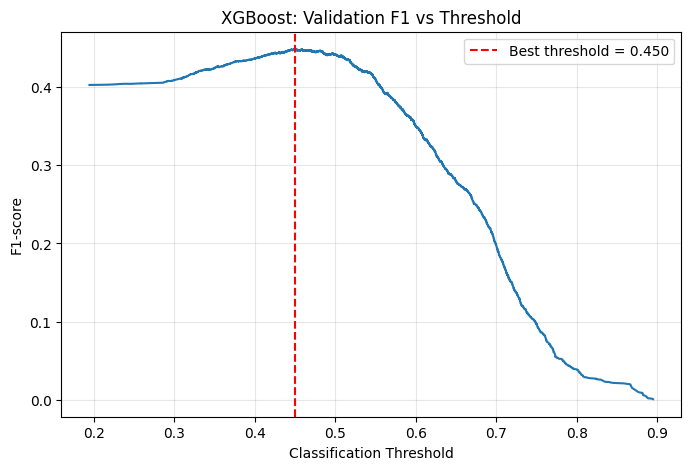

In [ ]:

from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val, y_val_prob
)

f1_values = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_idx = np.argmax(f1_values)
best_threshold = thresholds[best_idx]

print("Best threshold:", round(best_threshold, 4))
print("Best validation F1:", round(f1_values[best_idx], 4))

plt.figure(figsize=(8, 5))
plt.plot(thresholds, f1_values)
plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Best threshold = {best_threshold:.3f}"
)
plt.xlabel("Classification Threshold")
plt.ylabel("F1-score")
plt.title("XGBoost: Validation F1 vs Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


The threshold tuning results show that the best classification threshold is approximately 0.45, compared with the default threshold of 0.5. At this threshold, the model achieves its highest validation F1-score of approximately 0.45.

Lowering the threshold allows the model to identify more potential readmissions, which may improve recall while increasing the number of false positives. Overall, threshold tuning provides a small improvement in the balance between precision and recall.

## 5.5 XGBoost Final Test Set Evaluation

In [ ]:

y_test_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

y_test_pred = (
    y_test_prob >= best_threshold
).astype(int)

xgb_results = {
    "Model": "XGBoost",
    "AUROC": roc_auc_score(y_test, y_test_prob),
    "AUPRC": average_precision_score(y_test, y_test_prob),
    "Precision": precision_score(
        y_test, y_test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_test_pred, zero_division=0
    ),
    "F1": f1_score(
        y_test, y_test_pred, zero_division=0
    ),
    "Accuracy": accuracy_score(y_test, y_test_pred)
}

results_df = pd.DataFrame([xgb_results])

display(results_df.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_test_pred, zero_division=0
))


,Model,AUROC,AUPRC,Precision,Recall,F1,Accuracy
0,XGBoost,0.6556,0.407,0.3224,0.7175,0.4448,0.5485



Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.49      0.62     11369
           1       0.32      0.72      0.44      3833

    accuracy                           0.55     15202
   macro avg       0.58      0.60      0.53     15202
weighted avg       0.71      0.55      0.58     15202



The XGBoost model achieved a test AUROC of 0.6556 and an AUPRC of 0.4070, indicating moderate predictive ability for 30-day readmission among CKD patients.

Using the classification threshold selected from the validation set, the model achieved a precision of 0.3224, recall of 0.7175, and F1-score of 0.4448. The recall indicates that the model correctly identified approximately 71.75% of actual readmission cases. However, the relatively low precision of 32.24% suggests that many predicted readmissions were false positives.

The model achieved an accuracy of 54.85%, reflecting its tendency to identify more hospitalizations as potential readmissions. Overall, the results suggest that XGBoost can identify a substantial proportion of high-risk patients, but further improvements are needed to reduce false-positive predictions.

The similar AUROC and AUPRC results between the validation and test sets suggest relatively consistent discrimination performance on unseen patients.

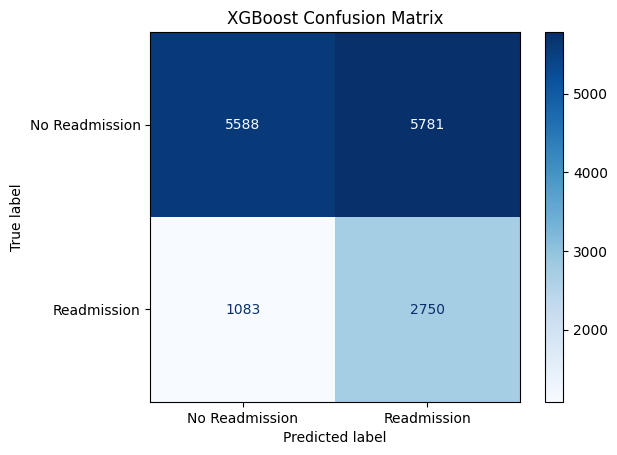

In [ ]:

cm = confusion_matrix(
    y_test, y_test_pred, labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Readmission", "Readmission"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("XGBoost Confusion Matrix")
plt.show()


The XGBoost confusion matrix shows that the model correctly identified 2,750 readmission cases and 5,588 non-readmission cases, while missing 1,083 actual readmissions and incorrectly predicting 5,781 non-readmission cases as readmissions.

The model achieved a recall of approximately 71.75%, indicating that it successfully identified most actual readmissions. However, precision was relatively low at 32.24%, suggesting a high number of false-positive predictions.

Overall, the model demonstrates a trade-off between identifying patients at risk of readmission and minimizing false-positive predictions.

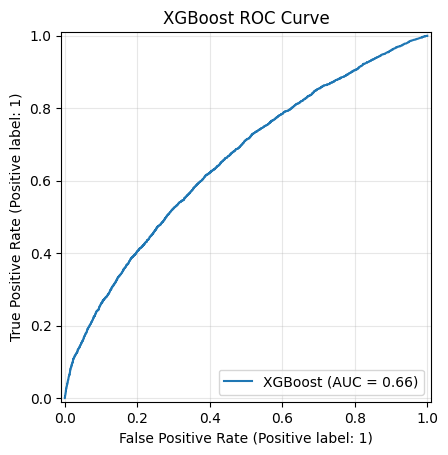

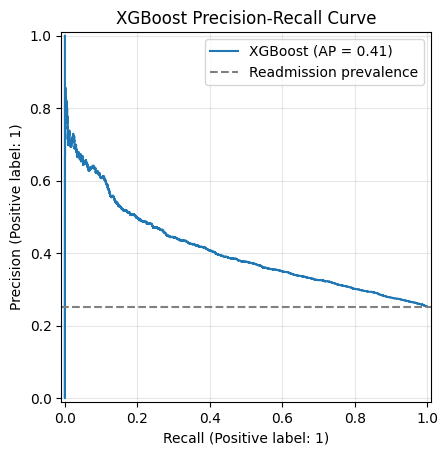

In [ ]:

RocCurveDisplay.from_predictions(
    y_test,
    y_test_prob,
    name="XGBoost"
)

plt.title("XGBoost ROC Curve")
plt.grid(alpha=0.3)
plt.show()

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_test_prob,
    name="XGBoost"
)

plt.axhline(
    y_test.mean(),
    linestyle="--",
    color="gray",
    label="Readmission prevalence"
)
plt.title("XGBoost Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


The ROC and Precision-Recall curves provide a visual evaluation of XGBoost performance across different classification thresholds. The model achieved an AUROC of 0.66 and an Average Precision of 0.41, which is higher than the readmission prevalence baseline of approximately 0.25.

The curves also show the trade-off between identifying more readmission cases and increasing false-positive predictions.

## 5.6 XGBoost Feature Importance Analysis

,Feature,Importance
7,num__prior_admissions_365d,0.231736
37,cat__marital_status_None,0.057488
8,num__prior_ed_visits_365d,0.047618
1,num__length_of_stay,0.042614
11,cat__admission_type_DIRECT EMER.,0.037503
17,cat__admission_type_SURGICAL SAME DAY ADMISSION,0.036900
9,num__medication_count,0.031036
3,num__heart_failure,0.030430
0,num__age,0.029674
15,cat__admission_type_EW EMER.,0.028196


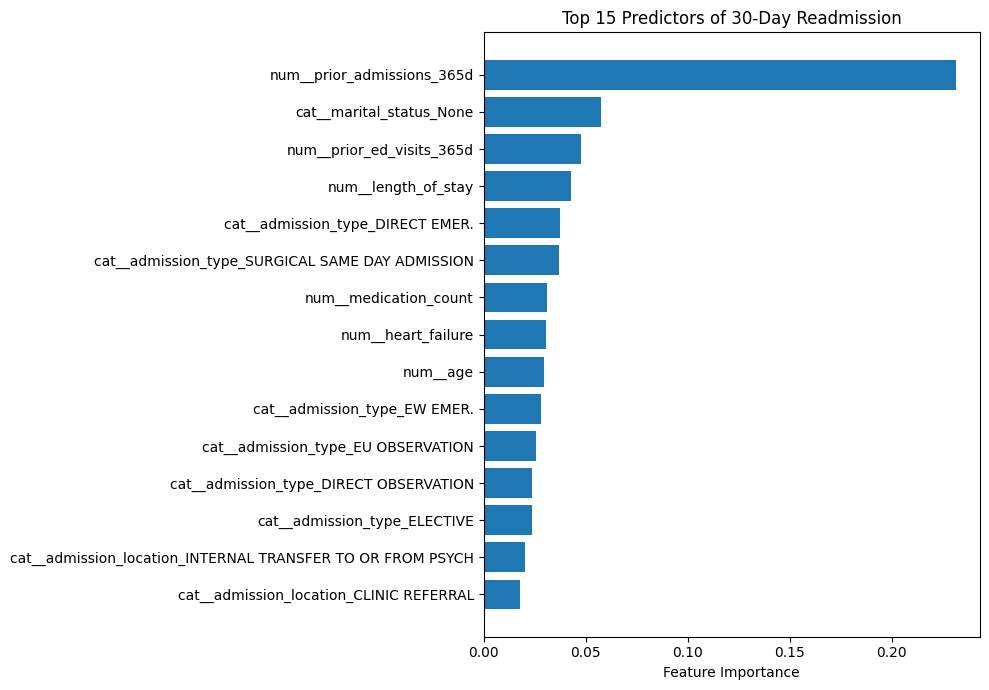

In [ ]:


feature_names = preprocessor.get_feature_names_out()


importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})


importance_df = importance_df.sort_values(
    "Importance", ascending=False
)


display(importance_df.head(20))


top_features = importance_df.head(15).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.title("Top 15 Predictors of 30-Day Readmission")
plt.tight_layout()
plt.show()


The feature importance analysis shows that previous hospital admissions within 365 days are the most important predictor in the XGBoost model, with an importance score of 0.2317. Other important features include marital status, previous emergency department visits, length of stay, and admission type.

These findings are consistent with our earlier EDA, which showed that patients with more previous hospitalizations and healthcare utilization tended to have higher readmission rates.

Heart failure also appears among the important features, suggesting that comorbidities may contribute to predicting 30-day readmission among CKD patients.

# 6. Random Forest

In [ ]:
rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# Parameters to test
param_grid = {
    "classifier__max_depth": [10, 15, 20, 25],
    "classifier__n_estimators": [100, 200, 300, 400, 500]
}

# Patient-level cross-validation
cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# GridSearchCV
gridSearch = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

# Fit training data
gridSearch.fit(
    X_train_final,
    y_train_final,
    groups=df.loc[X_train_final.index, "subject_id"]
)

print("Best AUC:", gridSearch.best_score_)
print("Best Parameters:", gridSearch.best_params_)


Fitting 3 folds for each of 20 candidates, totalling 60 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best AUC: 0.6607919970676619
Best Parameters: {'classifier__max_depth': 10, 'classifier__n_estimators': 500}


Training AUC: 0.7224
Testing AUC: 0.6588


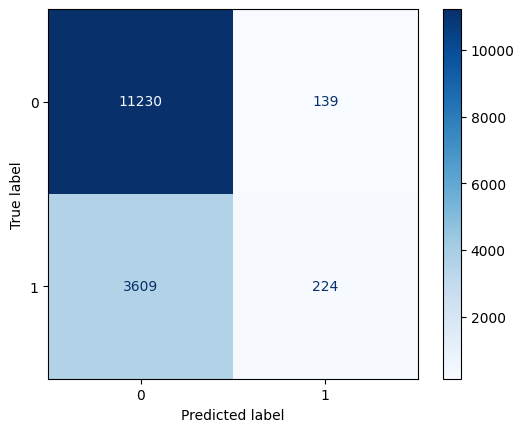

In [ ]:
#n_estimator=50, max_depth=10 are the best performing parameter out of the combination of n_estimator=[100,200,300,400,500],max=[10,15,20,25] by grid search
rf = RandomForestClassifier(n_estimators=500, max_depth=10, random_state=1)
rf.fit(X_train_processed, y_train_final)

# Training AUC
y_prob_rf_train = rf.predict_proba(X_train_processed)[:, 1]
print("Training AUC:", round(roc_auc_score(y_train_final, y_prob_rf_train), 4))

# Testing results
y_pred_rf = rf.predict(X_test_processed)
y_prob_rf = rf.predict_proba(X_test_processed)[:, 1]
print("Testing AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, cmap="Blues")

In [ ]:
# Calculate metrics
accuracy = accuracy_score(y_test, y_pred_rf)
precision = precision_score(y_test, y_pred_rf, zero_division=0)
recall = recall_score(y_test, y_pred_rf, zero_division=0)
f1 = f1_score(y_test, y_pred_rf, zero_division=0)

# Print metrics
print(f"Accuracy:    {accuracy:.4f}")
print(f"Precision:   {precision:.4f}")
print(f"Recall:      {recall:.4f}")
print(f"F1-Score:    {f1:.4f}")

Accuracy:    0.7535
Precision:   0.6171
Recall:      0.0584
F1-Score:    0.1068


,feature,importance
7,num__prior_admissions_365d,0.353228
8,num__prior_ed_visits_365d,0.107144
1,num__length_of_stay,0.104494
0,num__age,0.100898
9,num__medication_count,0.100130
3,num__heart_failure,0.017426
11,cat__admission_type_DIRECT EMER.,0.013238
37,cat__marital_status_None,0.013062
2,num__diabetes,0.012319
35,cat__marital_status_SINGLE,0.012077


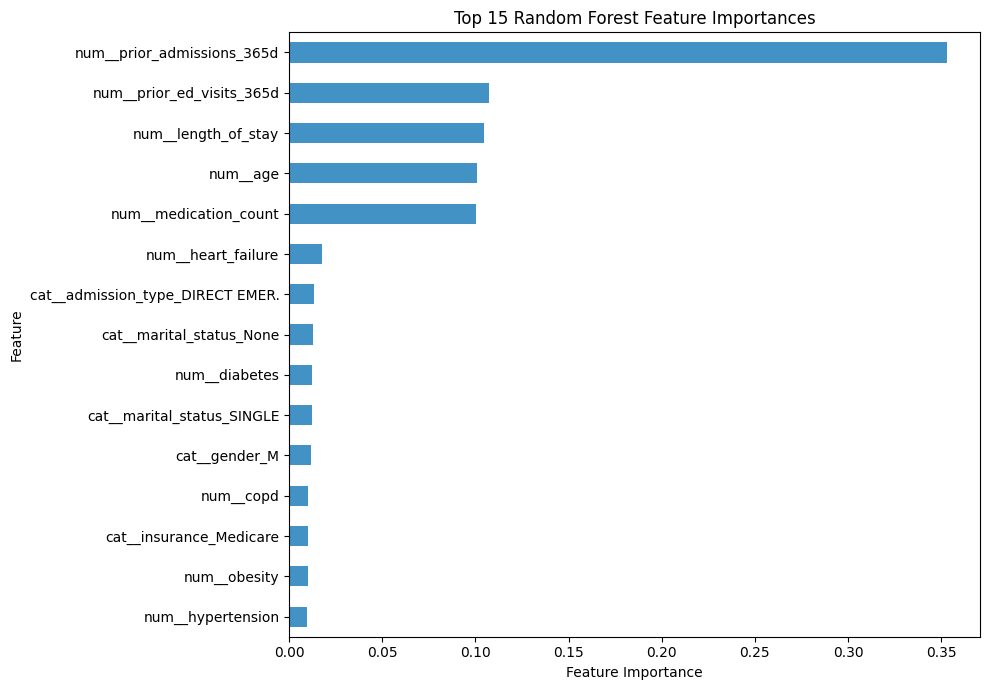

In [ ]:

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get Random Forest feature importances
importances = rf.feature_importances_

# Create DataFrame
df_rf = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

# Sort by importance
df_rf = df_rf.sort_values("importance", ascending=False)

# Display top 15 features
display(df_rf.head(15))

# Plot top 15 features
df_rf.head(15).plot(
    kind="barh",
    x="feature",
    y="importance",
    color="#4292C6",
    figsize=(10, 7),
    legend=False
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


# 7. Next Step